In [24]:
import warnings
warnings.filterwarnings('ignore')

## Importing important libraries

In [25]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedGroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, ExtraTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

# Optional gradient-boosting libraries. The notebook remains usable if one is absent.
try:
    from xgboost import XGBClassifier, XGBRFClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

try:
    from lightgbm import LGBMClassifier
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False

try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
except ImportError:
    HAS_CATBOOST = False

RANDOM_STATE = 42


This dataset is a cumulative record of all observed Kepler "objects of interest" — basically, all of the approximately 10,000 exoplanet candidates Kepler has taken observations on.

This dataset has an extensive data dictionary, which can be accessed here. Highlightable columns of note are:

1. KOI - Kepler Object of Interest.

2. kepoi_name: A KOI is a target identified by the Kepler Project that displays at least one transit-like sequence within Kepler time-series photometry that appears to be of astrophysical origin and initially consistent with a planetary transit hypothesis.

3. kepler_name: These names are intended to clearly indicate a class of objects that have been confirmed or validated as planets—a step up from the planet candidate designation.

4. koi_disposition: The disposition in the literature towards this exoplanet candidate. One of CANDIDATE, FALSE POSITIVE, NOT DISPOSITIONED or CONFIRMED.

5. koi_pdisposition: The disposition Kepler data analysis has towards this exoplanet candidate. One of FALSE POSITIVE, NOT DISPOSITIONED, and CANDIDATE.

6. koi_score: A value between 0 and 1 that indicates the confidence in the KOI disposition. For CANDIDATEs, a higher value indicates more confidence in its disposition, while for FALSE POSITIVEs, a higher value indicates less confidence in that disposition.

7. koi_fpflag_nt: A KOI whose light curve is not consistent with that of a transiting planet. This includes, but is not limited to, instrumental artifacts, non-eclipsing variable stars, and spurious (very low SNR) detections.

8. koi_fpflag_ss: A KOI that is observed to have a significant secondary event, transit shape, or out-of-eclipse variability, which indicates that the transit-like event is most likely caused by an eclipsing binary. However, self-luminous, hot Jupiters with a visible secondary eclipse will also have this flag set, but with a disposition of PC.

9. koi_fpflag_co: The source of the signal is from a nearby star, as inferred by measuring the centroid location of the image both in and out of transit, or by the strength of the transit signal in the target's outer (halo) pixels as compared to the transit signal from the pixels in the optimal (or core) aperture.

10. koi_srad: The photospheric radius of the star.

11. koi_kepmag: This is the Kepler band.

12. koi_period: The interval between consecutive planetary transits.


## Loading and preprocessing the data

In [26]:
df = pd.read_csv("Dataset\cumulative.csv")
df.head()


,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,1,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,2,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,3,10811496,K00753.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,4,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,5,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [27]:
df.tail(10)

,rowid,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
9554,9555,8308347,K03761.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,1,0,0,...,-174.0,4.603,0.066,-0.048,0.664,0.070,-0.064,294.89749,44.215790,15.473
9555,9556,2697935,K03853.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-141.0,3.508,0.187,-0.153,3.318,0.665,-0.813,287.46786,37.966640,10.630
9556,9557,8258160,K03870.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,...,-185.0,4.477,0.099,-0.121,0.857,0.138,-0.101,299.21881,44.181862,16.375
9557,9558,11911561,K03875.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,...,-181.0,4.027,0.434,-0.186,1.514,0.426,-0.640,290.14914,50.239178,13.579
9558,9559,8765560,K03891.01,NaN,CANDIDATE,CANDIDATE,1.000,0,0,0,...,-159.0,3.597,0.968,-0.242,2.780,1.089,-2.022,296.15601,44.920090,13.731
9559,9560,10031643,K07984.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,0,0,...,-152.0,4.296,0.231,-0.189,1.088,0.313,-0.228,298.74921,46.973351,14.478
9560,9561,10090151,K07985.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,1,...,-166.0,4.529,0.035,-0.196,0.903,0.237,-0.079,297.18875,47.093819,14.082
9561,9562,10128825,K07986.01,NaN,CANDIDATE,CANDIDATE,0.497,0,0,0,...,-220.0,4.444,0.056,-0.224,1.031,0.341,-0.114,286.50937,47.163219,14.757
9562,9563,10147276,K07987.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.021,0,0,1,...,-236.0,4.447,0.056,-0.224,1.041,0.341,-0.114,294.16489,47.176281,15.385
9563,9564,10156110,K07989.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,0,1,...,-225.0,4.385,0.054,-0.216,1.193,0.410,-0.137,297.00977,47.121021,14.826


In [28]:
df.shape

(9564, 50)

In [29]:
df.describe()

,rowid,kepid,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
count,9564.000000,9.564000e+03,8054.000000,9564.000000,9564.000000,9564.000000,9564.000000,9564.000000,9110.000000,9110.000000,...,9081.000000,9201.000000,9096.000000,9096.000000,9201.000000,9096.000000,9096.000000,9564.000000,9564.000000,9563.000000
mean,4782.500000,7.690628e+06,0.480829,0.188206,0.231598,0.194898,0.120033,75.671358,0.002148,-0.002148,...,-162.265059,4.310157,0.120738,-0.143161,1.728712,0.362292,-0.394806,292.060163,43.810433,14.264606
std,2761.033321,2.653459e+06,0.476928,0.390897,0.421875,0.396143,0.325018,1334.744046,0.008236,0.008236,...,72.746348,0.432606,0.132837,0.085477,6.127185,0.930870,2.168213,4.766657,3.601243,1.385448
min,1.000000,7.574500e+05,0.000000,0.000000,0.000000,0.000000,0.000000,0.241843,0.000000,-0.172500,...,-1762.000000,0.047000,0.000000,-1.207000,0.109000,0.000000,-116.137000,279.852720,36.577381,6.966000
25%,2391.750000,5.556034e+06,0.000000,0.000000,0.000000,0.000000,0.000000,2.733684,0.000005,-0.000276,...,-198.000000,4.218000,0.042000,-0.196000,0.829000,0.129000,-0.250000,288.660770,40.777173,13.440000
50%,4782.500000,7.906892e+06,0.334000,0.000000,0.000000,0.000000,0.000000,9.752831,0.000035,-0.000035,...,-160.000000,4.438000,0.070000,-0.128000,1.000000,0.251000,-0.111000,292.261125,43.677504,14.520000
75%,7173.250000,9.873066e+06,0.998000,0.000000,0.000000,0.000000,0.000000,40.715178,0.000276,-0.000005,...,-114.000000,4.543000,0.149000,-0.088000,1.345000,0.364000,-0.069000,295.859160,46.714611,15.322000
max,9564.000000,1.293514e+07,1.000000,1.000000,1.000000,1.000000,1.000000,129995.778400,0.172500,0.000000,...,0.000000,5.364000,1.472000,0.000000,229.908000,33.091000,0.000000,301.720760,52.336010,20.003000


In [30]:
df['koi_pdisposition'].value_counts()

koi_pdisposition
FALSE POSITIVE    5068
CANDIDATE         4496
Name: count, dtype: int64

<Axes: xlabel='koi_pdisposition', ylabel='count'>

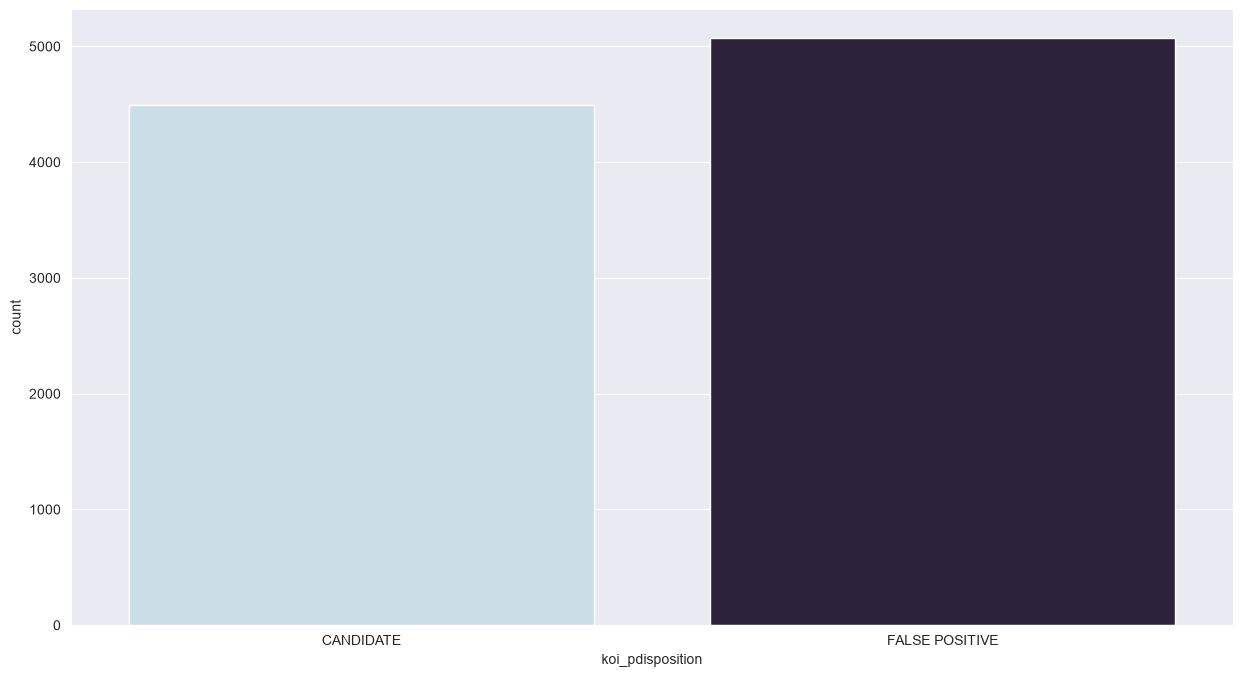

In [31]:
sns.set_style('darkgrid')
plt.figure(figsize=(15,8))
sns.countplot(x = df['koi_pdisposition'], palette = 'ch:s=.25,rot=-.25')

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 50 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   rowid              9564 non-null   int64  
 1   kepid              9564 non-null   int64  
 2   kepoi_name         9564 non-null   str    
 3   kepler_name        2294 non-null   str    
 4   koi_disposition    9564 non-null   str    
 5   koi_pdisposition   9564 non-null   str    
 6   koi_score          8054 non-null   float64
 7   koi_fpflag_nt      9564 non-null   int64  
 8   koi_fpflag_ss      9564 non-null   int64  
 9   koi_fpflag_co      9564 non-null   int64  
 10  koi_fpflag_ec      9564 non-null   int64  
 11  koi_period         9564 non-null   float64
 12  koi_period_err1    9110 non-null   float64
 13  koi_period_err2    9110 non-null   float64
 14  koi_time0bk        9564 non-null   float64
 15  koi_time0bk_err1   9110 non-null   float64
 16  koi_time0bk_err2   9110 non-null   

## Label Encoding the categorical target variable

In [33]:
# The target is encoded explicitly after filtering to the two expected classes.
# koi_disposition is deliberately not encoded because it will be excluded from predictors.
df["koi_pdisposition"].value_counts(dropna=False)


koi_pdisposition
FALSE POSITIVE    5068
CANDIDATE         4496
Name: count, dtype: int64

## Handling Missing Values

In [34]:
df.isnull().sum()

rowid                   0
kepid                   0
kepoi_name              0
kepler_name          7270
koi_disposition         0
koi_pdisposition        0
koi_score            1510
koi_fpflag_nt           0
koi_fpflag_ss           0
koi_fpflag_co           0
koi_fpflag_ec           0
koi_period              0
koi_period_err1       454
koi_period_err2       454
koi_time0bk             0
koi_time0bk_err1      454
koi_time0bk_err2      454
koi_impact            363
koi_impact_err1       454
koi_impact_err2       454
koi_duration            0
koi_duration_err1     454
koi_duration_err2     454
koi_depth             363
koi_depth_err1        454
koi_depth_err2        454
koi_prad              363
koi_prad_err1         363
koi_prad_err2         363
koi_teq               363
koi_teq_err1         9564
koi_teq_err2         9564
koi_insol             321
koi_insol_err1        321
koi_insol_err2        321
koi_model_snr         363
koi_tce_plnt_num      346
koi_tce_delivname     346
koi_steff   

In [35]:
# Keep the host-star identifier separately for group-aware evaluation.
# It will never be passed to a model as a predictor.
groups = df["kepid"].copy()

# Remove identifiers and metadata from the dataframe used for EDA/model features.
# The host-star ID is preserved separately in `groups`.
drop_columns = [
    "rowid", "kepoi_name", "kepler_name",
    "koi_teq_err1", "koi_teq_err2", "koi_tce_delivname"
]
df = df.drop(columns=drop_columns, errors="ignore")

In [36]:
numerical_columns = df.select_dtypes(include=["int64", "float64"]).columns
numerical_attributes = df[numerical_columns]


In [37]:
numerical_attributes

,kepid,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,1.000,0,0,0,0,9.488036,2.775000e-05,-2.775000e-05,170.538750,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,0.969,0,0,0,0,54.418383,2.479000e-04,-2.479000e-04,162.513840,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,0.000,0,1,0,0,19.899140,1.494000e-05,-1.494000e-05,175.850252,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,10848459,0.000,0,1,0,0,1.736952,2.630000e-07,-2.630000e-07,170.307565,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,10854555,1.000,0,0,0,0,2.525592,3.761000e-06,-3.761000e-06,171.595550,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9559,10031643,0.000,0,0,0,1,8.589871,1.846000e-04,-1.846000e-04,132.016100,...,-152.0,4.296,0.231,-0.189,1.088,0.313,-0.228,298.74921,46.973351,14.478
9560,10090151,0.000,0,1,1,0,0.527699,1.160000e-07,-1.160000e-07,131.705093,...,-166.0,4.529,0.035,-0.196,0.903,0.237,-0.079,297.18875,47.093819,14.082
9561,10128825,0.497,0,0,0,0,1.739849,1.780000e-05,-1.780000e-05,133.001270,...,-220.0,4.444,0.056,-0.224,1.031,0.341,-0.114,286.50937,47.163219,14.757
9562,10147276,0.021,0,0,1,0,0.681402,2.434000e-06,-2.434000e-06,132.181750,...,-236.0,4.447,0.056,-0.224,1.041,0.341,-0.114,294.16489,47.176281,15.385


In [38]:
df.isnull().mean()

kepid                0.000000
koi_disposition      0.000000
koi_pdisposition     0.000000
koi_score            0.157884
koi_fpflag_nt        0.000000
koi_fpflag_ss        0.000000
koi_fpflag_co        0.000000
koi_fpflag_ec        0.000000
koi_period           0.000000
koi_period_err1      0.047470
koi_period_err2      0.047470
koi_time0bk          0.000000
koi_time0bk_err1     0.047470
koi_time0bk_err2     0.047470
koi_impact           0.037955
koi_impact_err1      0.047470
koi_impact_err2      0.047470
koi_duration         0.000000
koi_duration_err1    0.047470
koi_duration_err2    0.047470
koi_depth            0.037955
koi_depth_err1       0.047470
koi_depth_err2       0.047470
koi_prad             0.037955
koi_prad_err1        0.037955
koi_prad_err2        0.037955
koi_teq              0.037955
koi_insol            0.033563
koi_insol_err1       0.033563
koi_insol_err2       0.033563
koi_model_snr        0.037955
koi_tce_plnt_num     0.036177
koi_steff            0.037955
koi_steff_

In [39]:
# Imputation will be fitted only on each training fold inside the modelling pipeline.
df.isnull().sum().sort_values(ascending=False).head(15)


koi_score            1510
koi_steff_err2        483
koi_slogg_err1        468
koi_srad_err1         468
koi_slogg_err2        468
koi_steff_err1        468
koi_srad_err2         468
koi_time0bk_err1      454
koi_time0bk_err2      454
koi_period_err2       454
koi_period_err1       454
koi_duration_err2     454
koi_depth_err2        454
koi_duration_err1     454
koi_impact_err1       454
dtype: int64

## Correlation heatmap

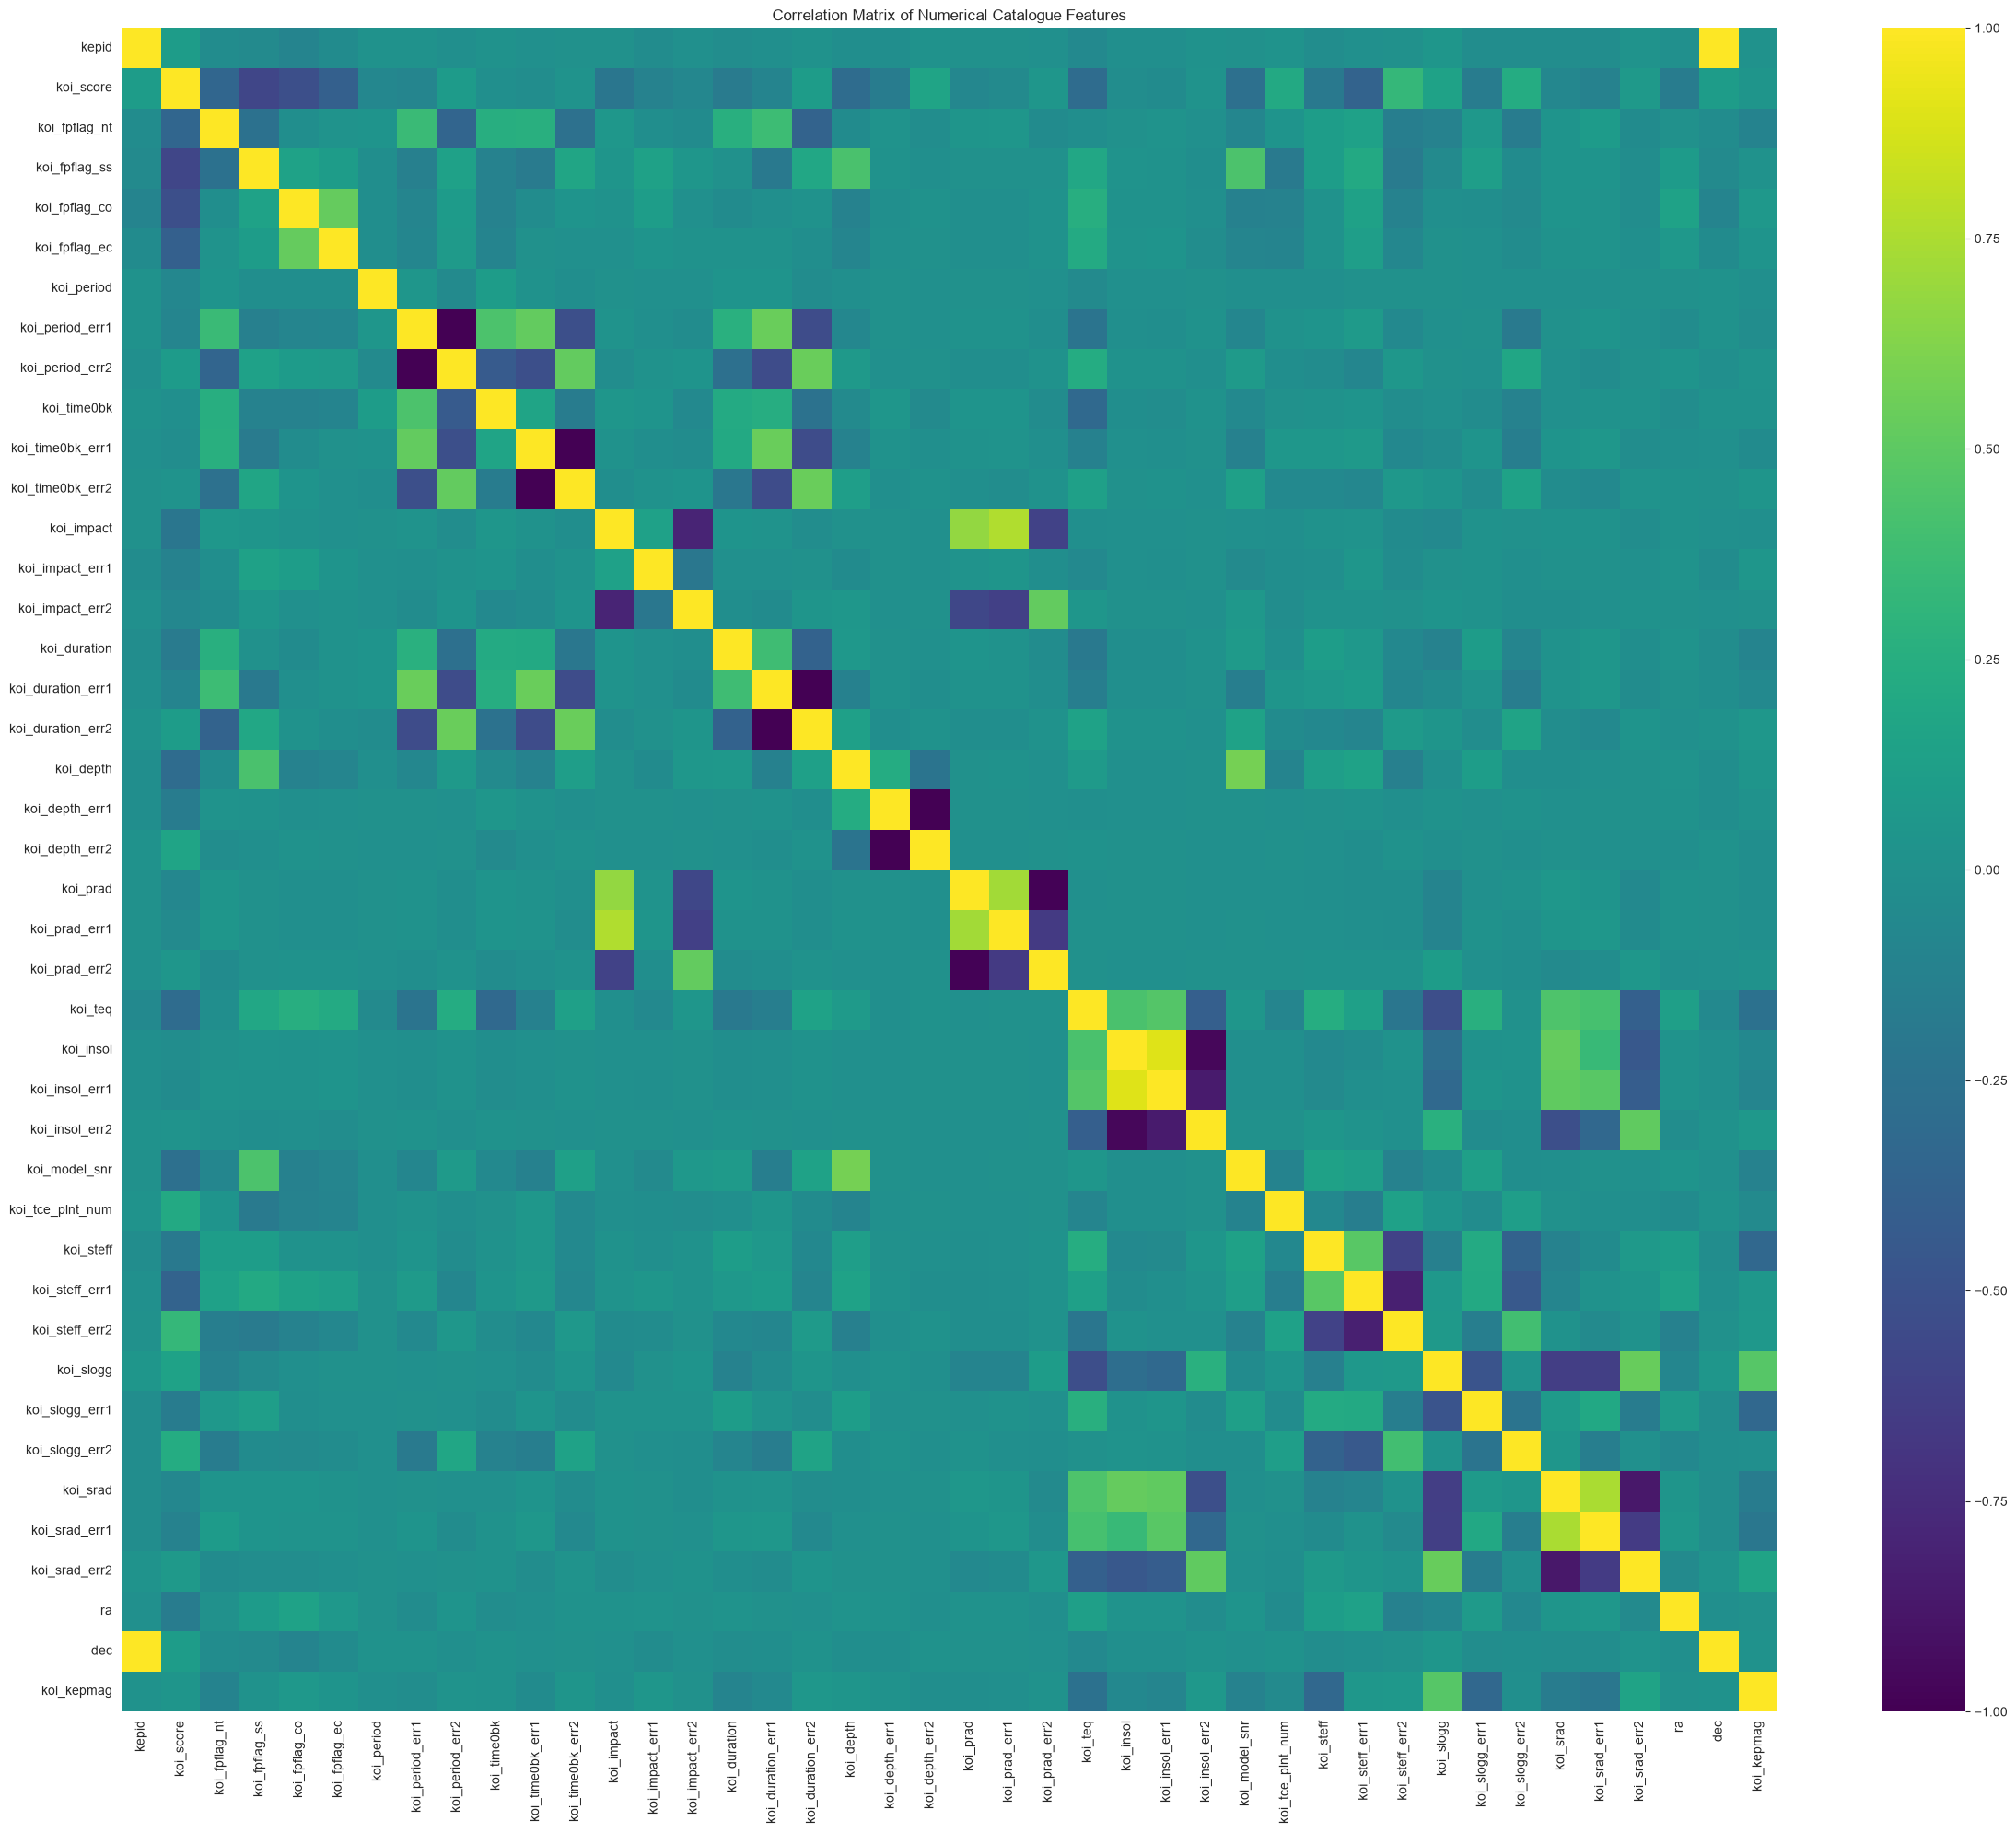

In [40]:
# Exploratory correlation view only. Missing values are handled later in the pipeline.
eda_numeric = df.select_dtypes(include=np.number)
plt.figure(figsize=(24, 20))
sns.heatmap(eda_numeric.corr(), cmap="viridis", center=0)
plt.title("Correlation Matrix of Numerical Catalogue Features")
plt.tight_layout()
plt.show()


## Outliers detection

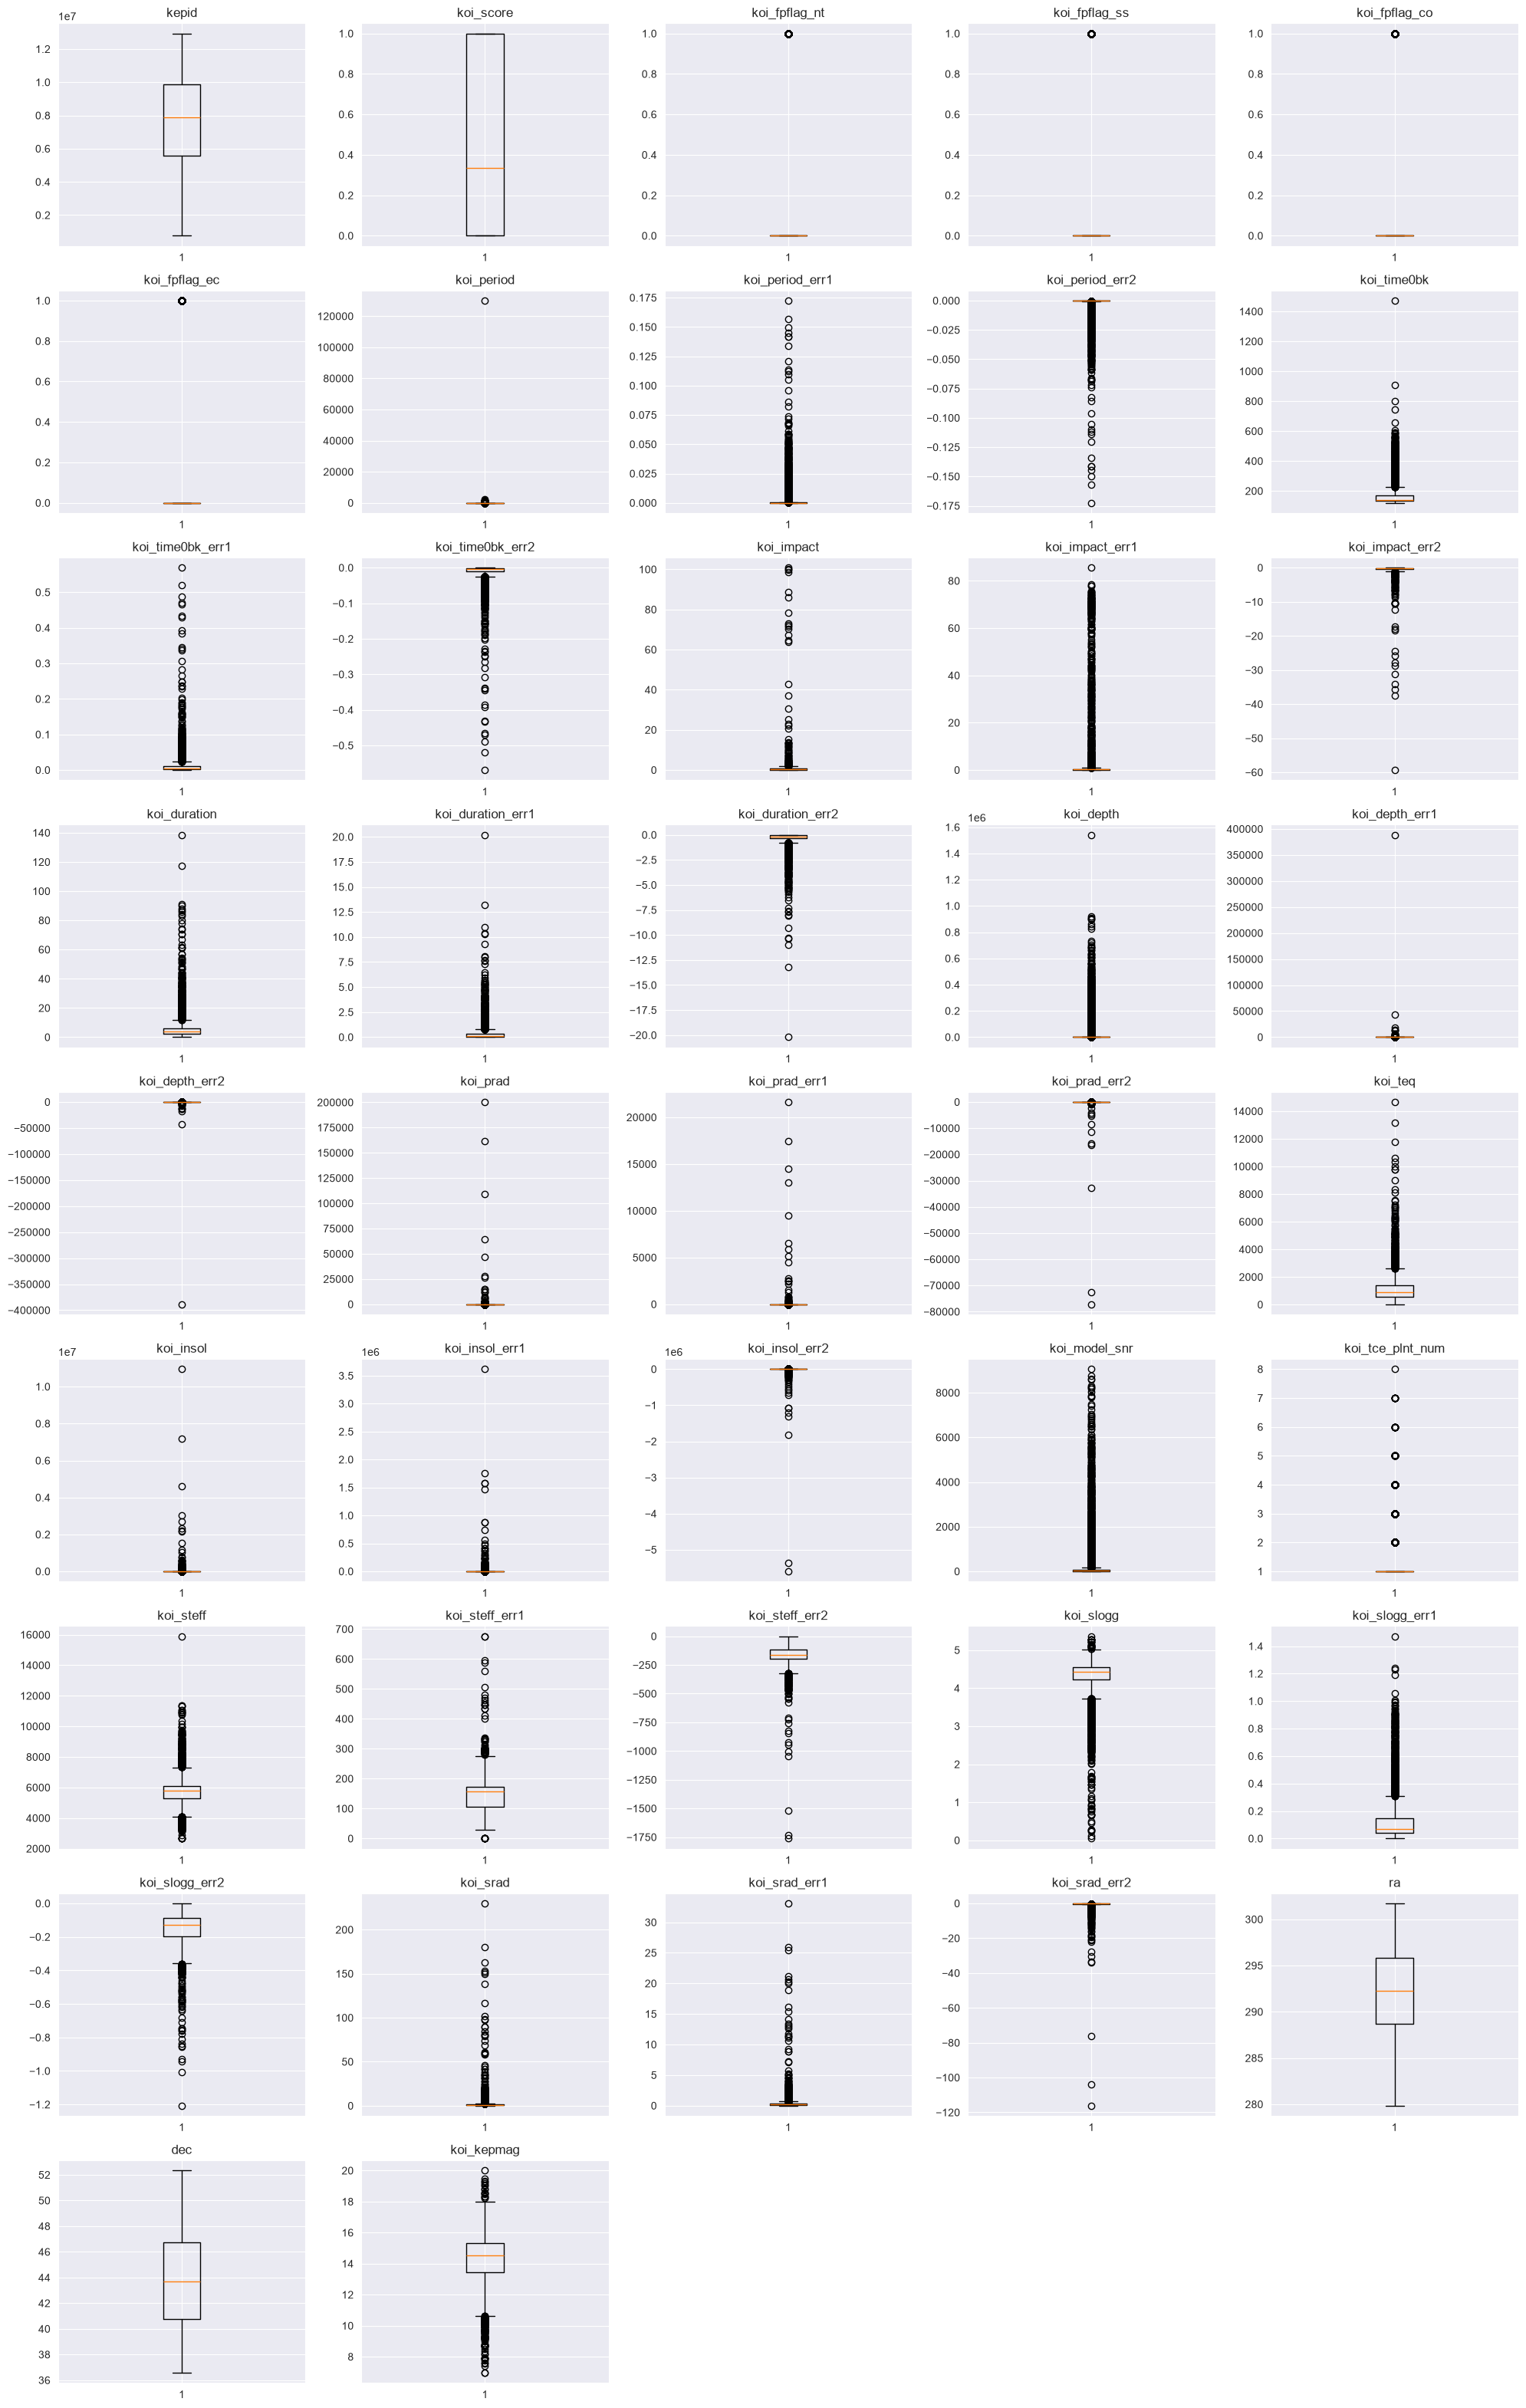

In [41]:
num_attributes = len(numerical_attributes.columns)
num_cols = 5
num_rows = -(-num_attributes // num_cols)

fig, axes = plt.subplots(
    nrows=num_rows, ncols=num_cols,
    figsize=(4 * num_cols, 3.5 * num_rows)
)
axes = np.array(axes).reshape(-1)

for i, col in enumerate(numerical_attributes.columns):
    axes[i].boxplot(numerical_attributes[col].dropna())
    axes[i].set_title(col)

for ax in axes[num_attributes:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


In [42]:
# Binary target: 0 = FALSE POSITIVE, 1 = CANDIDATE.
target_map = {"FALSE POSITIVE": 0, "CANDIDATE": 1}
y = df["koi_pdisposition"].map(target_map)

if y.isna().any():
    unexpected = df.loc[y.isna(), "koi_pdisposition"].unique()
    raise ValueError(f"Unexpected or missing target labels: {unexpected}")

# Exclude labels and features potentially derived from the disposition process.
# These are excluded for a conservative first experiment.
leakage_prone_columns = [
    "koi_disposition", "koi_score",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
    "koi_tce_plnt_num"
]
X = df.drop(columns=["koi_pdisposition"] + leakage_prone_columns + ["kepid"],
            errors="ignore")
X = X.select_dtypes(include=np.number).copy()

# Remove columns that contain no observed values.
all_missing = X.columns[X.isna().all()].tolist()
if all_missing:
    X = X.drop(columns=all_missing)

# Align group identifiers and target to the same rows.
groups = groups.loc[X.index]

print("Feature matrix:", X.shape)
print("Number of unique host stars:", groups.nunique())
print("Target distribution:")
print(y.value_counts().rename(index={0: "FALSE POSITIVE", 1: "CANDIDATE"}))
print("Excluded disposition-related columns:", leakage_prone_columns)
print("All-missing columns removed:", all_missing)

Feature matrix: (9564, 35)
Number of unique host stars: 8214
Target distribution:
koi_pdisposition
FALSE POSITIVE    5068
CANDIDATE         4496
Name: count, dtype: int64
Excluded disposition-related columns: ['koi_disposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec', 'koi_tce_plnt_num']
All-missing columns removed: []


## Group-aware training and test split

In [43]:
# Group-aware holdout split.
# All KOIs associated with a given host star are assigned to either train or test,
# never both. A 5-fold split gives approximately 80% train / 20% test.
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(outer_cv.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# Explicitly verify that no host star appears in both partitions.
overlap = set(groups_train.unique()).intersection(set(groups_test.unique()))
assert len(overlap) == 0, f"Group leakage detected for {len(overlap)} host stars."

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("Unique training host stars:", groups_train.nunique())
print("Unique test host stars:", groups_test.nunique())
print("Host-star overlap:", len(overlap))


Training set: (7650, 35)
Test set: (1914, 35)
Unique training host stars: 6572
Unique test host stars: 1642
Host-star overlap: 0


Why group by kepid? Multiple KOIs can be associated with the same target star. A row-wise random split could place one candidate from a star in training and another candidate from that same star in testing. Grouping by kepid tests generalisation to host stars not seen during training.

### Leakage-aware model development

The target is `koi_pdisposition`. The second disposition field (`koi_disposition`), the confidence score (`koi_score`), Kepler false-positive flags, and the TCE planet number are excluded from predictors in this conservative baseline because they may encode information related to the disposition process.

The host-star identifier (`kepid`) is retained separately as a grouping variable, but never used as a predictor. A StratifiedGroupKFold split ensures that candidates associated with the same host star cannot appear in both the training and test partitions.

All remaining numerical predictors are imputed and scaled inside scikit-learn pipelines. Cross-validation is performed on the training partition only, with preprocessing re-fitted independently inside each fold.

### Leakage-safe preprocessing

Median imputation and standardisation are fitted only on the training portion of each fold because both operations are inside the model pipeline. The held-out test partition is not used for model fitting or cross-validation.

## Machine-learning Models

In [44]:
# Every estimator receives the same leakage-safe preprocessing pipeline.
# Scaling is retained for consistency across models; tree-based models do not require it, but it does not use information from validation/test observations.

classifiers = [
    LogisticRegression(max_iter=2000, class_weight="balanced"),
    DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    RandomForestClassifier(
        n_estimators=400, random_state=RANDOM_STATE,
        class_weight="balanced", n_jobs=-1
    ),
    GaussianNB(),
    ExtraTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    AdaBoostClassifier(random_state=RANDOM_STATE),
    KNeighborsClassifier(n_neighbors=5)
]
names = [
    "Logistic_Regression", "Decision_Tree", "Random_Forest", "Gaussian_NB",
    "Extra_Tree", "Hist_Gradient_Boosting", "AdaBoost", "KNN"
]

if HAS_XGBOOST:
    classifiers.extend([
        XGBClassifier(
            n_estimators=400, max_depth=6, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8,
            eval_metric="logloss", random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        XGBRFClassifier(
            n_estimators=400, max_depth=8,
            subsample=0.8, colsample_bytree=0.8,
            eval_metric="logloss", random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ])
    names.extend(["XGBoost", "XGBoost_RF"])

if HAS_LIGHTGBM:
    classifiers.append(LGBMClassifier(
        n_estimators=400, learning_rate=0.05,
        random_state=RANDOM_STATE, class_weight="balanced",
        verbosity=-1
    ))
    names.append("LightGBM")

if HAS_CATBOOST:
    classifiers.append(CatBoostClassifier(
        iterations=400, learning_rate=0.05, depth=6,
        verbose=False, random_seed=RANDOM_STATE,
        auto_class_weights="Balanced"
    ))
    names.append("CatBoost")

def make_pipeline(estimator):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", estimator)
    ])

pipelines = {name: make_pipeline(model) for name, model in zip(names, classifiers)}
print("Models available:", list(pipelines))


Models available: ['Logistic_Regression', 'Decision_Tree', 'Random_Forest', 'Gaussian_NB', 'Extra_Tree', 'Hist_Gradient_Boosting', 'AdaBoost', 'KNN', 'XGBoost', 'XGBoost_RF', 'LightGBM', 'CatBoost']


## group-aware Cross Validation

In [45]:
# Group-aware cross-validation on the training partition only.
# Each host star is confined to one validation fold.
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_rows = []
for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )
    cv_rows.append({
        "Model": name,
        **{f"CV_{metric}_Mean": np.mean(scores[f"test_{metric}"])
           for metric in scoring},
        **{f"CV_{metric}_Std": np.std(scores[f"test_{metric}"])
           for metric in scoring}
    })

cv_results = pd.DataFrame(cv_rows).set_index("Model")
cv_results.sort_values("CV_f1_Mean", ascending=False)


,CV_accuracy_Mean,CV_precision_Mean,CV_recall_Mean,CV_f1_Mean,CV_roc_auc_Mean,CV_average_precision_Mean,CV_accuracy_Std,CV_precision_Std,CV_recall_Std,CV_f1_Std,CV_roc_auc_Std,CV_average_precision_Std
Model,,,,,,,,,,,,
CatBoost,0.850982,0.848997,0.830924,0.839795,0.924603,0.920641,0.003616,0.008221,0.008724,0.003798,0.003712,0.005400
XGBoost,0.850984,0.857320,0.819525,0.837911,0.925556,0.922203,0.008670,0.011559,0.013842,0.009647,0.003020,0.004685
LightGBM,0.848499,0.850325,0.822582,0.836162,0.923109,0.918079,0.005309,0.007253,0.011063,0.006215,0.002557,0.004815
Hist_Gradient_Boosting,0.847845,0.851908,0.818688,0.834916,0.924281,0.919320,0.004611,0.005758,0.010494,0.005648,0.003316,0.004973
Random_Forest,0.845885,0.854652,0.810066,0.831696,0.920461,0.916634,0.006289,0.010646,0.009339,0.006662,0.003109,0.004038
XGBoost_RF,0.834643,0.830236,0.815072,0.822519,0.916427,0.910387,0.006903,0.011152,0.009014,0.006998,0.003775,0.005767
AdaBoost,0.817129,0.813604,0.792827,0.802994,0.893144,0.885433,0.012528,0.016206,0.015107,0.013264,0.006937,0.008533
Logistic_Regression,0.784576,0.741328,0.832037,0.784039,0.866279,0.842956,0.005173,0.004048,0.010946,0.006109,0.006195,0.005781
KNN,0.784053,0.760421,0.789490,0.774627,0.853727,0.807182,0.005537,0.008257,0.008770,0.005376,0.008950,0.017798


In [46]:
# Select the best model using cross-validation F1-score.
# The test partition is not used for model selection.
best_model_name = cv_results["CV_f1_Mean"].idxmax()

print("Best model based on mean CV F1:", best_model_name)

# Retrieve the selected pipeline and fit it on the complete training partition.
best_model = pipelines[best_model_name]
best_model.fit(X_train, y_train)

# Evaluate the selected model once on the held-out test partition.
y_pred = best_model.predict(X_test)

test_results = {
    "Test Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0)
}

if hasattr(best_model, "predict_proba"):
    y_score = best_model.predict_proba(X_test)[:, 1]
    test_results["ROC_AUC"] = roc_auc_score(y_test, y_score)
    test_results["PR_AUC"] = average_precision_score(y_test, y_score)
elif hasattr(best_model, "decision_function"):
    y_score = best_model.decision_function(X_test)
    test_results["ROC_AUC"] = roc_auc_score(y_test, y_score)
    test_results["PR_AUC"] = average_precision_score(y_test, y_score)

print("\nFinal held-out test results:")
display(pd.DataFrame([test_results], index=[best_model_name]))

Best model based on mean CV F1: CatBoost

Final held-out test results:


,Test Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
CatBoost,0.855799,0.842105,0.853333,0.847682,0.929384,0.919294


# Confusion Matrix of all the best Model

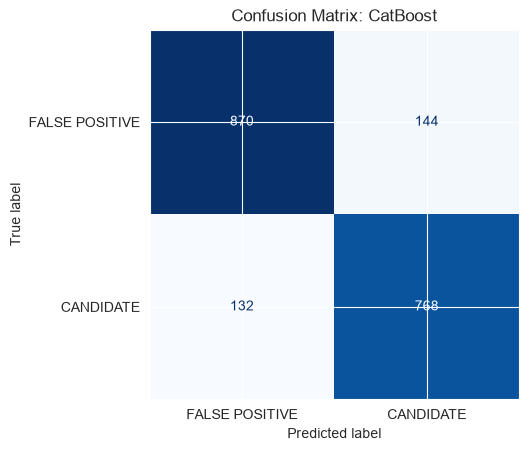

In [47]:
# Confusion matrix for the selected model on the held-out test partition.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["FALSE POSITIVE", "CANDIDATE"],
    cmap="Blues",
    colorbar=False
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.show()

In [48]:
# Classification report for the selected model.
print(f"Classification Report: {best_model_name}\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=["FALSE POSITIVE", "CANDIDATE"],
    zero_division=0
))

Classification Report: CatBoost

                precision    recall  f1-score   support

FALSE POSITIVE       0.87      0.86      0.86      1014
     CANDIDATE       0.84      0.85      0.85       900

      accuracy                           0.86      1914
     macro avg       0.86      0.86      0.86      1914
  weighted avg       0.86      0.86      0.86      1914



In [49]:
# Compare all models using training-partition cross-validation only.
cv_results.sort_values(
    by="CV_f1_Mean",
    ascending=False
)

,CV_accuracy_Mean,CV_precision_Mean,CV_recall_Mean,CV_f1_Mean,CV_roc_auc_Mean,CV_average_precision_Mean,CV_accuracy_Std,CV_precision_Std,CV_recall_Std,CV_f1_Std,CV_roc_auc_Std,CV_average_precision_Std
Model,,,,,,,,,,,,
CatBoost,0.850982,0.848997,0.830924,0.839795,0.924603,0.920641,0.003616,0.008221,0.008724,0.003798,0.003712,0.005400
XGBoost,0.850984,0.857320,0.819525,0.837911,0.925556,0.922203,0.008670,0.011559,0.013842,0.009647,0.003020,0.004685
LightGBM,0.848499,0.850325,0.822582,0.836162,0.923109,0.918079,0.005309,0.007253,0.011063,0.006215,0.002557,0.004815
Hist_Gradient_Boosting,0.847845,0.851908,0.818688,0.834916,0.924281,0.919320,0.004611,0.005758,0.010494,0.005648,0.003316,0.004973
Random_Forest,0.845885,0.854652,0.810066,0.831696,0.920461,0.916634,0.006289,0.010646,0.009339,0.006662,0.003109,0.004038
XGBoost_RF,0.834643,0.830236,0.815072,0.822519,0.916427,0.910387,0.006903,0.011152,0.009014,0.006998,0.003775,0.005767
AdaBoost,0.817129,0.813604,0.792827,0.802994,0.893144,0.885433,0.012528,0.016206,0.015107,0.013264,0.006937,0.008533
Logistic_Regression,0.784576,0.741328,0.832037,0.784039,0.866279,0.842956,0.005173,0.004048,0.010946,0.006109,0.006195,0.005781
KNN,0.784053,0.760421,0.789490,0.774627,0.853727,0.807182,0.005537,0.008257,0.008770,0.005376,0.008950,0.017798


In [50]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.keras.utils.set_random_seed(RANDOM_STATE)


In [51]:
# Dimensions of the grouped training and test feature matrices.
print("Training:", X_train.shape)
print("Test:", X_test.shape)


Training: (7650, 35)
Test: (1914, 35)


In [52]:
# Group-aware validation split within the training partition.
# This keeps host stars separate across fit and validation subsets.
inner_holdout = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)
fit_idx, val_idx = next(
    inner_holdout.split(X_train, y_train, groups=groups_train)
)

X_fit_raw = X_train.iloc[fit_idx]
X_val_raw = X_train.iloc[val_idx]
y_fit_dl = y_train.iloc[fit_idx]
y_val_dl = y_train.iloc[val_idx]

# Fit imputation and scaling only on the MLP fitting subset.
dl_imputer = SimpleImputer(strategy="median")
dl_scaler = StandardScaler()

X_fit_dl = dl_imputer.fit_transform(X_fit_raw)
X_val_dl = dl_imputer.transform(X_val_raw)
X_test_dl = dl_imputer.transform(X_test)

X_fit_dl = dl_scaler.fit_transform(X_fit_dl)
X_val_dl = dl_scaler.transform(X_val_dl)
X_test_dl = dl_scaler.transform(X_test_dl)

# MLP is appropriate as a baseline for tabular catalogue features.
model = models.Sequential([
    layers.Input(shape=(X_fit_dl.shape[1],)),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

early_stopping = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

print("MLP fit subset:", X_fit_dl.shape)
print("MLP validation subset:", X_val_dl.shape)
print("MLP test subset:", X_test_dl.shape)
print("Fit-validation host overlap:",
      len(set(groups_train.iloc[fit_idx]).intersection(
          set(groups_train.iloc[val_idx]))))


MLP fit subset: (6119, 35)
MLP validation subset: (1531, 35)
MLP test subset: (1914, 35)
Fit-validation host overlap: 0


In [53]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
history = model.fit(
    X_fit_dl, y_fit_dl,
    epochs=100,
    batch_size=32,
    validation_data=(X_val_dl, y_val_dl),
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.7369 - loss: 0.5319 - precision: 0.7234 - recall: 0.7128 - roc_auc: 0.8167 - val_accuracy: 0.7825 - val_loss: 0.6260 - val_precision: 0.7760 - val_recall: 0.7556 - val_roc_auc: 0.8611
Epoch 2/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7918 - loss: 0.4570 - precision: 0.7764 - recall: 0.7823 - roc_auc: 0.8695 - val_accuracy: 0.8040 - val_loss: 0.6204 - val_precision: 0.8061 - val_recall: 0.7681 - val_roc_auc: 0.8756
Epoch 3/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8055 - loss: 0.4439 - precision: 0.8009 - recall: 0.7803 - roc_auc: 0.8786 - val_accuracy: 0.8034 - val_loss: 0.5277 - val_precision: 0.8095 - val_recall: 0.7611 - val_roc_auc: 0.8815
Epoch 4/100
192/192 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8109 - loss: 0.4178 - precision: 0.8080 - recall: 0.7841 - roc_auc: 0.8901 - val_accuracy: 0.8080 - val_loss: 0.4977 - val_precision: 0.8170 - val_recall: 0.7625 - val_roc_auc: 0.

In [55]:
# Evaluate the neural network once on the untouched test partition.
dl_test_metrics = model.evaluate(X_test_dl, y_test, verbose=0)
dict(zip(model.metrics_names, dl_test_metrics))


{'loss': 0.3871263861656189, 'compile_metrics': 0.8396029472351074}

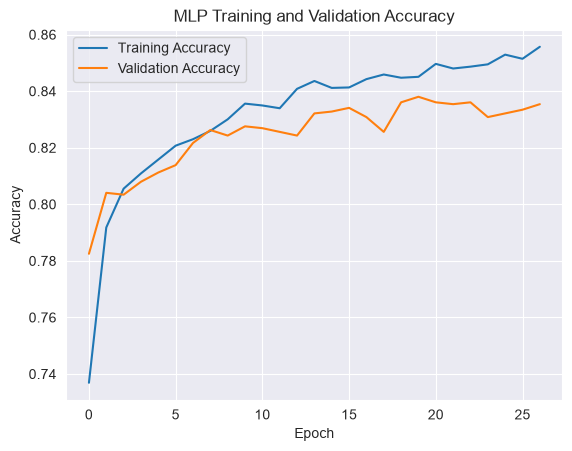

In [56]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("MLP Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


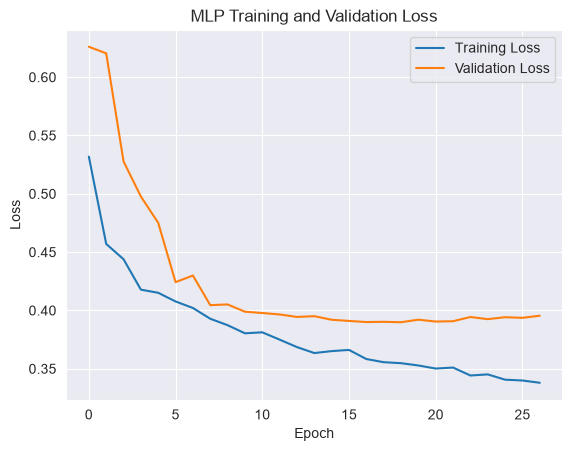

In [57]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("MLP Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


                precision    recall  f1-score   support

FALSE POSITIVE       0.84      0.86      0.85      1014
     CANDIDATE       0.83      0.82      0.83       900

      accuracy                           0.84      1914
     macro avg       0.84      0.84      0.84      1914
  weighted avg       0.84      0.84      0.84      1914



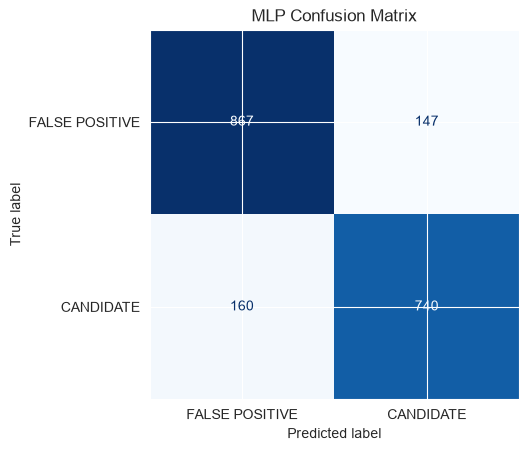

In [58]:
# Correct binary classification thresholding and confusion matrix.
y_pred_prob = model.predict(X_test_dl, verbose=0).ravel()
y_pred_dl = (y_pred_prob >= 0.5).astype(int)

print(classification_report(
    y_test, y_pred_dl,
    target_names=["FALSE POSITIVE", "CANDIDATE"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dl,
    display_labels=["FALSE POSITIVE", "CANDIDATE"],
    cmap="Blues", colorbar=False
)
plt.title("MLP Confusion Matrix")
plt.show()
